Device: cpu
[train.csv] fid_col='Unnamed: 0' (exists~1.000)
[validate.csv] fid_col='idx' (exists~1.000)
[test.csv] fid_col='idx' (exists~1.000)
sizes: 8425 2872 2875
channel mean: [-51.620277 -48.298088 -95.15732 ] std: [107.63025 109.47314 170.32104]
logM mean/std: 0.4511817991733551 0.15172851085662842
y_proxy mean/std: -2305.912841796875 2668.9482421875
Batch shapes: torch.Size([64, 3, 32, 32]) torch.Size([64]) torch.Size([64]) torch.Size([64])
Epoch 1/35 | loss 0.7215 | Val RMSE_dex 0.1588 | Val sig68 0.1298 | Val R2 -0.0102 | Val yRMSE(std) 0.0427
Epoch 2/35 | loss 0.6588 | Val RMSE_dex 0.1585 | Val sig68 0.1296 | Val R2 -0.0062 | Val yRMSE(std) 0.0301
Epoch 3/35 | loss 0.6573 | Val RMSE_dex 0.1568 | Val sig68 0.1292 | Val R2 0.0155 | Val yRMSE(std) 0.0324
Epoch 4/35 | loss 0.6572 | Val RMSE_dex 0.1572 | Val sig68 0.1287 | Val R2 0.0103 | Val yRMSE(std) 0.0611
Epoch 5/35 | loss 0.6528 | Val RMSE_dex 0.1549 | Val sig68 0.1267 | Val R2 0.0387 | Val yRMSE(std) 0.0976
Epoch 6/35 | los

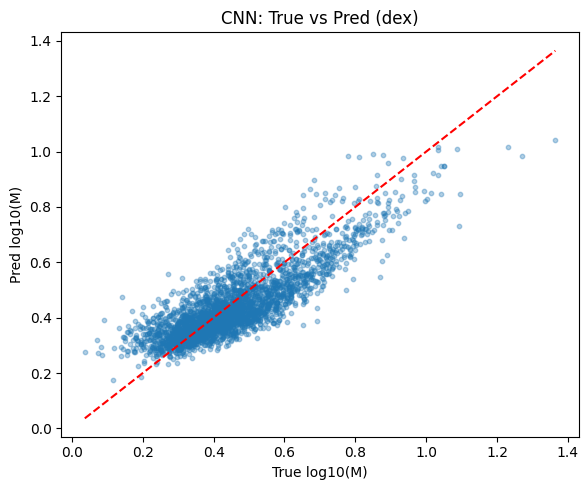

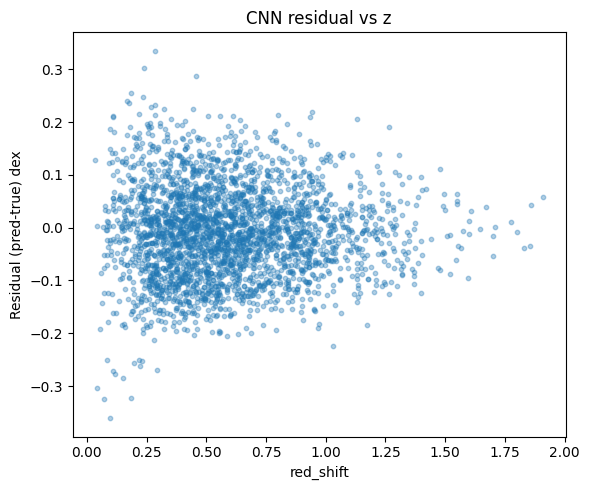

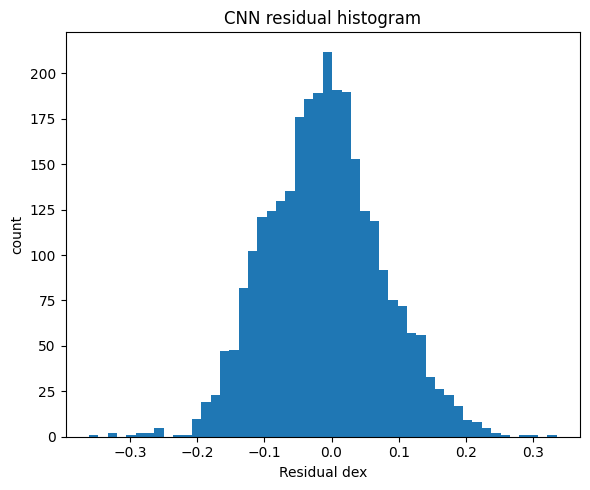

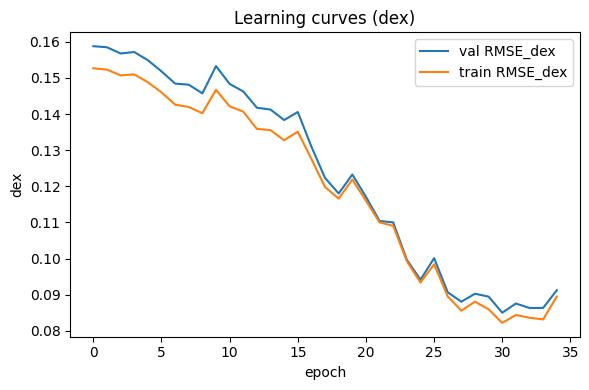

In [ ]:
import os
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import r2_score

csv_dir = r"storage/data/description/ACT"
fits_base = r"storage/data/ACT"

train_csv = os.path.join(csv_dir, "train.csv")
val_csv   = os.path.join(csv_dir, "validate.csv")
test_csv  = os.path.join(csv_dir, "test.csv")

train_fits = os.path.join(fits_base, "train")
val_fits   = os.path.join(fits_base, "validate")
test_fits  = os.path.join(fits_base, "test")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def load_df(path, fits_folder):
    df = pd.read_csv(path)

    
    if "source" in df.columns and df["source"].dtype == object:
        src = df["source"].astype(str).str.lower() == "dr5"
    else:
        src = (df["source"] == "dr5") if "source" in df.columns else True

    tgt = (df["target"] == 1) if "target" in df.columns else True
    df = df[tgt & src & (~df["M"].isna())].copy()

    
    def exists_frac(col):
        if col not in df.columns: return -1.0
        s = df.head(min(2000, len(df)))
        ok = 0; tot = 0
        for v in s[col].values:
            if pd.isna(v): continue
            fid = int(v); tot += 1
            if os.path.exists(os.path.join(fits_folder, f"{fid}.fits")):
                ok += 1
        return ok / max(tot, 1)

    cands = ["Unnamed: 0", "idx"]
    fracs = {c: exists_frac(c) for c in cands}
    fid_col = max(fracs, key=fracs.get)
    if fracs[fid_col] < 0.5:
        raise KeyError(f"Could not find usable fid column for {path}. Fractions={fracs}. Columns={df.columns.tolist()}")

    print(f"[{os.path.basename(path)}] fid_col='{fid_col}' (exists~{fracs[fid_col]:.3f})")
    df["fid"] = df[fid_col].astype(int)

    if "red_shift" not in df.columns:
        df["red_shift"] = np.nan

    return df

train_df = load_df(train_csv, train_fits)
val_df   = load_df(val_csv,   val_fits)
test_df  = load_df(test_csv,  test_fits)

print("sizes:", len(train_df), len(val_df), len(test_df))


def y_proxy_from_img(img3, r_ap=5, ring=(10,14), channel=0):
    ch = img3[channel] 
    H, W = ch.shape
    cy, cx = H//2, W//2
    yy, xx = np.ogrid[:H, :W]
    rr2 = (yy-cy)**2 + (xx-cx)**2

    mask_ap = rr2 <= r_ap*r_ap
    r1, r2 = ring
    mask_ring = (rr2 >= r1*r1) & (rr2 <= r2*r2)

    ring_vals = ch[mask_ring]
    bg = np.median(ring_vals) if ring_vals.size else np.median(ch)

    
    return float((ch[mask_ap] - bg).sum())


def compute_channel_mean_std(df, folder, n=4000):
    take = df.sample(min(n, len(df)), random_state=42)
    s1 = np.zeros(3, dtype=np.float64)
    s2 = np.zeros(3, dtype=np.float64)
    cnt = 0
    for _, row in take.iterrows():
        path = os.path.join(folder, f"{int(row['fid'])}.fits")
        if not os.path.exists(path): 
            continue
        img = fits.getdata(path).astype(np.float32)
        if img.ndim != 3 or img.shape[0] != 3:
            continue
        flat = img.reshape(3, -1)
        s1 += flat.mean(axis=1)
        s2 += (flat**2).mean(axis=1)
        cnt += 1
    mean = s1 / max(cnt,1)
    var  = s2 / max(cnt,1) - mean**2
    std  = np.sqrt(np.maximum(var, 1e-6))
    return mean.astype(np.float32), std.astype(np.float32)

mean_c, std_c = compute_channel_mean_std(train_df, train_fits, n=4000)
print("channel mean:", mean_c, "std:", std_c)

logM_train = np.log10(train_df["M"].values).astype(np.float32)
logM_mu = float(logM_train.mean())
logM_sd = float(logM_train.std() + 1e-6)
print("logM mean/std:", logM_mu, logM_sd)

# compute y_proxy stats from a subset for speed
def compute_yproxy_stats(df, folder, n=4000):
    take = df.sample(min(n, len(df)), random_state=1)
    ys = []
    for _, row in take.iterrows():
        path = os.path.join(folder, f"{int(row['fid'])}.fits")
        if not os.path.exists(path): 
            continue
        img = fits.getdata(path).astype(np.float32)
        if img.ndim != 3: 
            continue
        ys.append(y_proxy_from_img(img, r_ap=5, ring=(10,14), channel=0))
    ys = np.array(ys, dtype=np.float32)
    return float(ys.mean()), float(ys.std() + 1e-6)

y_mu, y_sd = compute_yproxy_stats(train_df, train_fits, n=4000)
print("y_proxy mean/std:", y_mu, y_sd)

def zfill(x):
    return float(x) if np.isfinite(x) else 0.0


class ClusterCnnDataset(Dataset):
    def __init__(self, df, folder, mean_c, std_c):
        self.df = df.reset_index(drop=True)
        self.folder = folder
        self.mean_c = mean_c
        self.std_c = std_c

    def __len__(self): return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        fid = int(row["fid"])
        path = os.path.join(self.folder, f"{fid}.fits")

        img = fits.getdata(path).astype(np.float32) 
        if img.ndim == 2:
            img = img[None, :, :]

        
        img = (img - self.mean_c[:,None,None]) / self.std_c[:,None,None]
        img = np.clip(img, -8, 8)

        yproxy = y_proxy_from_img(img, r_ap=5, ring=(10,14), channel=0)

        logM = np.float32(np.log10(float(row["M"])))
        z = zfill(row["red_shift"])

        yproxy_std = (np.float32(yproxy) - np.float32(y_mu)) / np.float32(y_sd)
        logM_std   = (logM - np.float32(logM_mu)) / np.float32(logM_sd)

        return (
            torch.tensor(img, dtype=torch.float32),
            torch.tensor(yproxy_std, dtype=torch.float32),
            torch.tensor(logM_std, dtype=torch.float32),
            torch.tensor(z, dtype=torch.float32),
        )

train_ds = ClusterCnnDataset(train_df, train_fits, mean_c, std_c)
val_ds   = ClusterCnnDataset(val_df,   val_fits,   mean_c, std_c)
test_ds  = ClusterCnnDataset(test_df,  test_fits,  mean_c, std_c)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=128, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=128, shuffle=False)

xb, yb, mb, zb = next(iter(train_loader))
print("Batch shapes:", xb.shape, yb.shape, mb.shape, zb.shape)


class YThenMassNet(nn.Module):
    def __init__(self, use_z=True):
        super().__init__()
        self.use_z = use_z

        self.backbone = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),  # 16x16
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),  # 8x8
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1)          # 64x1x1
        )

        self.y_head = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1)
        )

        in_mass = 1 + (1 if use_z else 0) 
        self.mass_head = nn.Sequential(
            nn.Linear(in_mass, 32), nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x, z=None):
        feat = self.backbone(x).flatten(1)    
        y_hat = self.y_head(feat).squeeze(1)    

        if self.use_z:
            if z is None:
                raise ValueError("use_z=True but z is None")
            inp = torch.stack([y_hat, z], dim=1) 
        else:
            inp = y_hat.unsqueeze(1)           

        m_hat = self.mass_head(inp).squeeze(1) 
        return y_hat, m_hat

model = YThenMassNet(use_z=True).to(device)


loss_y = nn.SmoothL1Loss(beta=0.2)
loss_m = nn.SmoothL1Loss(beta=0.2)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

LAMBDA_Y = 0.5  
EPOCHS = 35

def unstd_logM(m_std):
    return m_std * logM_sd + logM_mu

def evaluate(loader, split_name=""):
    model.eval()
    ypreds=[]; ytrues=[]
    mpreds=[]; mtrues=[]
    zs=[]
    with torch.no_grad():
        for x, y, m, z in loader:
            x=x.to(device); y=y.to(device); m=m.to(device); z=z.to(device)
            y_hat, m_hat = model(x, z)
            ypreds.append(y_hat.cpu().numpy()); ytrues.append(y.cpu().numpy())
            mpreds.append(m_hat.cpu().numpy()); mtrues.append(m.cpu().numpy())
            zs.append(z.cpu().numpy())

    ypreds=np.concatenate(ypreds); ytrues=np.concatenate(ytrues)
    mpreds=np.concatenate(mpreds); mtrues=np.concatenate(mtrues)
    zs=np.concatenate(zs)

    
    pred_logM = unstd_logM(mpreds)
    true_logM = unstd_logM(mtrues)
    resid = pred_logM - true_logM
    rmse_dex = float(np.sqrt(np.mean(resid**2)))
    sig68 = float(np.quantile(np.abs(resid), 0.68))
    r2 = float(r2_score(true_logM, pred_logM))

    
    y_rmse = float(np.sqrt(np.mean((ypreds - ytrues)**2)))
    return rmse_dex, sig68, r2, y_rmse, pred_logM, true_logM, resid, zs

best_val = 1e9
best_state = None
hist = {"train_rmse":[], "val_rmse":[], "val_r2":[], "val_y_rmse":[]}

for ep in range(1, EPOCHS+1):
    model.train()
    tot=0.0
    for x, y, m, z in train_loader:
        x=x.to(device); y=y.to(device); m=m.to(device); z=z.to(device)
        optimizer.zero_grad()
        y_hat, m_hat = model(x, z)

        ly = loss_y(y_hat, y)
        lm = loss_m(m_hat, m)
        loss = lm + LAMBDA_Y * ly

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        tot += float(loss.item())

    tr_rmse, tr_s68, tr_r2, tr_y_rmse, *_ = evaluate(train_loader, "train")
    va_rmse, va_s68, va_r2, va_y_rmse, *_ = evaluate(val_loader, "val")
    hist["train_rmse"].append(tr_rmse)
    hist["val_rmse"].append(va_rmse)
    hist["val_r2"].append(va_r2)
    hist["val_y_rmse"].append(va_y_rmse)

    if va_rmse < best_val:
        best_val = va_rmse
        best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}

    print(f"Epoch {ep}/{EPOCHS} | loss {tot/len(train_loader):.4f} | "
          f"Val RMSE_dex {va_rmse:.4f} | Val sig68 {va_s68:.4f} | Val R2 {va_r2:.4f} | Val yRMSE(std) {va_y_rmse:.4f}")


if best_state is not None:
    model.load_state_dict(best_state)

te_rmse, te_s68, te_r2, te_y_rmse, pred_logM, true_logM, resid, zs = evaluate(test_loader, "test")
print("\nTEST:")
print("RMSE_dex:", te_rmse)
print("sig68_dex:", te_s68)
print("R2:", te_r2)
print("yRMSE(std):", te_y_rmse)
print("Requirement (<=0.25 dex):", "OK" if te_rmse <= 0.25 else "NOT OK")


plt.figure(figsize=(6,5))
plt.scatter(true_logM, pred_logM, s=10, alpha=0.35)
mn = float(min(true_logM.min(), pred_logM.min()))
mx = float(max(true_logM.max(), pred_logM.max()))
plt.plot([mn,mx],[mn,mx],"r--")
plt.xlabel("True log10(M)")
plt.ylabel("Pred log10(M)")
plt.title("CNN: True vs Pred (dex)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,5))
plt.scatter(zs, resid, s=10, alpha=0.35)
plt.xlabel("red_shift")
plt.ylabel("Residual (pred-true) dex")
plt.title("CNN residual vs z")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,5))
plt.hist(resid, bins=50)
plt.xlabel("Residual dex")
plt.ylabel("count")
plt.title("CNN residual histogram")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,4))
plt.plot(hist["val_rmse"], label="val RMSE_dex")
plt.plot(hist["train_rmse"], label="train RMSE_dex")
plt.xlabel("epoch"); plt.ylabel("dex")
plt.title("Learning curves (dex)")
plt.legend()
plt.tight_layout()
plt.show()